<a href="https://colab.research.google.com/github/Ag3-S/Neural-Networks-Lab/blob/main/Experiment5_Regularization.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Experiment 5: 5-Layer Neural Network on CAT data with Regularization and Cross Validation

Part A (this and the next sections) contains the step-by-step building blocks (activation functions, initialization, forward / backward propagation, cost, update) and the loading of the cat / non-cat data.
Part B (from **Section 8** onward) builds a **5-layer NN**, runs **K-fold cross validation**, and compares **LASSO, RIDGE, Elastic Net, Dropout, DropConnect and Batch Normalization**.

**After this assignment you will be able to:**
- Use non-linear units like ReLU to improve your model
- Build a deeper neural network (with more than 1 hidden layer)
- Implement regularization techniques (L1, L2, Elastic Net, Dropout, DropConnect, Batch Norm) from scratch
- Use cross validation and compare variance across techniques

**Notation**:
- Superscript $[l]$ denotes a quantity associated with the $l^{th}$ layer.
    - Example: $a^{[L]}$ is the $L^{th}$ layer activation. $W^{[L]}$ and $b^{[L]}$ are the $L^{th}$ layer parameters.
- Superscript $(i)$ denotes a quantity associated with the $i^{th}$ example.
    - Example: $x^{(i)}$ is the $i^{th}$ training example.
- Lowerscript $i$ denotes the $i^{th}$ entry of a vector.
    - Example: $a^{[l]}_i$ denotes the $i^{th}$ entry of the $l^{th}$ layer's activations).

Let's get started!

## 1 - Packages

Let's first import all the packages that you will need during this assignment.
- [numpy](www.numpy.org) is the main package for scientific computing with Python.
- [matplotlib](http://matplotlib.org) is a library to plot graphs in Python.
- np.random.seed(1) is used to keep all the random function calls consistent. It will help us grade your work. Please don't change the seed.

In [ ]:
!pip install h5py

In [ ]:
import numpy as np
import h5py
import matplotlib.pyplot as plt

##
#%matplotlib inline
#plt.rcParams['figure.figsize'] = (5.0, 4.0) # set default size of plots
#plt.rcParams['image.interpolation'] = 'nearest'
#plt.rcParams['image.cmap'] = 'gray'

#%load_ext autoreload
#%autoreload 2

np.random.seed(1)

##  2- Some Important Functions that will  be used later

In [ ]:
def sigmoid(Z):

    A = 1/(1+np.exp(-Z))
    cache = Z

    return A, cache

In [ ]:
def relu(Z):

    A = np.maximum(0,Z)

    assert(A.shape == Z.shape)

    cache = Z
    return A, cache

In [ ]:
def relu_backward(dA, cache):


    Z = cache
    dZ = np.array(dA, copy=True) # just converting dz to a correct object.

    # When z <= 0, you should set dz to 0 as well.
    dZ[Z <= 0] = 0

    assert (dZ.shape == Z.shape)

    return dZ

In [ ]:
def sigmoid_backward(dA, cache):


    Z = cache

    s = 1/(1+np.exp(-Z))
    dZ = dA * s * (1-s)

    assert (dZ.shape == Z.shape)

    return dZ

## 3 - Outline

To build your neural network, you need several "helper functions". Each small helper function you will implement will have detailed instructions that will walk you through the necessary steps. Here is an outline of this notebook, you will:

- Initialize the parameters for a two-layer network and for an $L$-layer neural network.
- Implement the forward propagation module (shown in purple in the figure below).
     - Complete the LINEAR part of a layer's forward propagation step (resulting in $Z^{[l]}$).
     - We give you the ACTIVATION function (relu/sigmoid).
     - Combine the previous two steps into a new [LINEAR->ACTIVATION] forward function.
     - Stack the [LINEAR->RELU] forward function L-1 time (for layers 1 through L-1) and add a [LINEAR->SIGMOID] at the end (for the final layer $L$). This gives you a new L_model_forward function.
- Compute the loss.
- Implement the backward propagation module (denoted in red in the figure below).
    - Complete the LINEAR part of a layer's backward propagation step.
    - We give you the gradient of the ACTIVATE function (relu_backward/sigmoid_backward)
    - Combine the previous two steps into a new [LINEAR->ACTIVATION] backward function.
    - Stack [LINEAR->RELU] backward L-1 times and add [LINEAR->SIGMOID] backward in a new L_model_backward function
- Finally update the parameters.


**Note** that for every forward function, there is a corresponding backward function. That is why at every step of your forward module you will be storing some values in a cache. The cached values are useful for computing gradients. In the backpropagation module you will then use the cache to calculate the gradients. This notebook will show you exactly how to carry out each of these steps.

## 4 - Initialization

We will write two helper functions that will initialize the parameters for your model. The first function will be used to initialize parameters for a two layer model. The second one will generalize this initialization process to $L$ layers.

###  2-layer Neural Network

**Instructions**:
- The model's structure is: *LINEAR -> RELU -> LINEAR -> SIGMOID*.
- Use random initialization for the weight matrices. Use `np.random.randn(shape)*0.01` with the correct shape.
- Use zero initialization for the biases. Use `np.zeros(shape)`.

In [ ]:

def initialize_parameters(n_x, n_h, n_y):

    np.random.seed(1)

    W1 = np.random.randn(n_h,n_x)*0.01
    b1 = np.zeros((n_h,1))
    W2 = np.random.randn(n_y,n_h)*0.01
    b2 = np.zeros((n_y,1))
    parameters = {"W1": W1,
                  "b1": b1,
                  "W2": W2,
                  "b2": b2}

    return parameters

In [ ]:
parameters = initialize_parameters(3,2,1)
print("W1 = " + str(parameters["W1"]))
print("b1 = " + str(parameters["b1"]))
print("W2 = " + str(parameters["W2"]))
print("b2 = " + str(parameters["b2"]))

W1 = [[ 0.01624345 -0.00611756 -0.00528172]
 [-0.01072969  0.00865408 -0.02301539]]
b1 = [[0.]
 [0.]]
W2 = [[ 0.01744812 -0.00761207]]
b2 = [[0.]]


### L-layer Neural Network

The initialization for a deeper L-layer neural network is more complicated because there are many more weight matrices and bias vectors. When completing the `initialize_parameters_deep`, you should make sure that your dimensions match between each layer. Recall that $n^{[l]}$ is the number of units in layer $l$. Thus for example if the size of our input $X$ is $(12288, 209)$ (with $m=209$ examples) then:


Remember that when we compute $W X + b$ in python, it carries out broadcasting. For example, if:

$$ W = \begin{bmatrix}
    j  & k  & l\\
    m  & n & o \\
    p  & q & r
\end{bmatrix}\;\;\; X = \begin{bmatrix}
    a  & b  & c\\
    d  & e & f \\
    g  & h & i
\end{bmatrix} \;\;\; b =\begin{bmatrix}
    s  \\
    t  \\
    u
\end{bmatrix}\tag{2}$$

Then $WX + b$ will be:

$$ WX + b = \begin{bmatrix}
    (ja + kd + lg) + s  & (jb + ke + lh) + s  & (jc + kf + li)+ s\\
    (ma + nd + og) + t & (mb + ne + oh) + t & (mc + nf + oi) + t\\
    (pa + qd + rg) + u & (pb + qe + rh) + u & (pc + qf + ri)+ u
\end{bmatrix}\tag{3}  $$

**Instructions**:
- The model's structure is *[LINEAR -> RELU] $ \times$ (L-1) -> LINEAR -> SIGMOID*. I.e., it has $L-1$ layers using a ReLU activation function followed by an output layer with a sigmoid activation function.
- Use random initialization for the weight matrices. Use `np.random.randn(shape) * 0.01`.
- Use zeros initialization for the biases. Use `np.zeros(shape)`.
- We will store $n^{[l]}$, the number of units in different layers, in a variable `layer_dims`.

For example, the `layer_dims` for the "Planar Data classification model" in this notebook would have been [2,4,1]: There were two inputs, one hidden layer with 4 hidden units, and an output layer with 1 output unit. This means `W1`'s shape was (4,2), `b1` was (4,1), `W2` was (1,4) and `b2` was (1,1). Now you will generalize this to $L$ layers!
- Here is the implementation for $L=1$ (one layer neural network). It should inspire you to implement the general case (L-layer neural network).
```python
    if L == 1:
        parameters["W" + str(L)] = np.random.randn(layer_dims[1], layer_dims[0]) * 0.01
        parameters["b" + str(L)] = np.zeros((layer_dims[1], 1))
```

In [ ]:

def initialize_parameters_deep(layer_dims):

    np.random.seed(3)
    parameters = {}
    L = len(layer_dims)            # number of layers in the network

    for l in range(1, L):
        parameters['W' + str(l)] = np.random.randn(layer_dims[l], layer_dims[l-1]) * 0.01
        parameters['b' + str(l)] = np.zeros((layer_dims[l], 1))

    return parameters

In [ ]:
parameters = initialize_parameters_deep([5,4,3])
print("W1 = " + str(parameters["W1"]))
print("b1 = " + str(parameters["b1"]))
print("W2 = " + str(parameters["W2"]))
print("b2 = " + str(parameters["b2"]))

W1 = [[ 0.01788628  0.0043651   0.00096497 -0.01863493 -0.00277388]
 [-0.00354759 -0.00082741 -0.00627001 -0.00043818 -0.00477218]
 [-0.01313865  0.00884622  0.00881318  0.01709573  0.00050034]
 [-0.00404677 -0.0054536  -0.01546477  0.00982367 -0.01101068]]
b1 = [[0.]
 [0.]
 [0.]
 [0.]]
W2 = [[-0.01185047 -0.0020565   0.01486148  0.00236716]
 [-0.01023785 -0.00712993  0.00625245 -0.00160513]
 [-0.00768836 -0.00230031  0.00745056  0.01976111]]
b2 = [[0.]
 [0.]
 [0.]]


## 5 - Forward propagation module

### Linear Forward
Now that you have initialized your parameters, you will do the forward propagation module. You will start by implementing some basic functions that you will use later when implementing the model. You will complete three functions in this order:

- LINEAR
- LINEAR -> ACTIVATION where ACTIVATION will be either ReLU or Sigmoid.
- [LINEAR -> RELU] $\times$ (L-1) -> LINEAR -> SIGMOID (whole model)

The linear forward module (vectorized over all the examples) computes the following equations:

$$Z^{[l]} = W^{[l]}A^{[l-1]} +b^{[l]}\tag{4}$$

where $A^{[0]} = X$.


**Reminder**:
The mathematical representation of this unit is $Z^{[l]} = W^{[l]}A^{[l-1]} +b^{[l]}$. You may also find `np.dot()` useful. If your dimensions don't match, printing `W.shape` may help.

In [ ]:

def linear_forward(A, W, b):

    Z = np.dot(W,A) +b

    cache = (A, W, b)

    return Z, cache

### 4.2 - Linear-Activation Forward

In this notebook, you will use two activation functions:

- **Sigmoid**: $\sigma(Z) = \sigma(W A + b) = \frac{1}{ 1 + e^{-(W A + b)}}$. We have provided you with the `sigmoid` function. This function returns **two** items: the activation value "`a`" and a "`cache`" that contains "`Z`" (it's what we will feed in to the corresponding backward function). To use it you could just call:
``` python
A, activation_cache = sigmoid(Z)
```

- **ReLU**: The mathematical formula for ReLu is $A = RELU(Z) = max(0, Z)$. We have provided you with the `relu` function. This function returns **two** items: the activation value "`A`" and a "`cache`" that contains "`Z`" (it's what we will feed in to the corresponding backward function). To use it you could just call:
``` python
A, activation_cache = relu(Z)
```

For more convenience, you are going to group two functions (Linear and Activation) into one function (LINEAR->ACTIVATION). Hence, you will implement a function that does the LINEAR forward step followed by an ACTIVATION forward step.
Exercise: Implement the forward propagation of the LINEAR->ACTIVATION layer. Mathematical relation is:
𝐴
[𝑙]
=𝑔(
𝑍
[𝑙]
)=𝑔(
𝑊
[𝑙]
𝐴
[𝑙−1]
+
𝑏
[𝑙]
)
A[l]=g(Z[l])=g(W[l]A[l−1]+b[l])
where the activation "g" can be sigmoid() or relu(). Use linear_forward() and the correct activation function.

In [ ]:

def linear_activation_forward(A_prev, W, b, activation):

    if activation == "sigmoid":
        # Inputs: "A_prev, W, b". Outputs: "A, activation_cache".

        Z, linear_cache = linear_forward(A_prev, W, b)
        A, activation_cache = sigmoid(Z)


    elif activation == "relu":
        # Inputs: "A_prev, W, b". Outputs: "A, activation_cache".

        Z, linear_cache = linear_forward(A_prev, W, b)
        A, activation_cache = relu(Z)


    cache = (linear_cache, activation_cache)

    return A, cache

### d) L-Layer Model

For even more convenience when implementing the $L$-layer Neural Net, you will need a function that replicates the previous one (`linear_activation_forward` with RELU) $L-1$ times, then follows that with one `linear_activation_forward` with SIGMOID.

Implementing the forward propagation of the above model.

**Instruction**: In the code below, the variable `AL` will denote $A^{[L]} = \sigma(Z^{[L]}) = \sigma(W^{[L]} A^{[L-1]} + b^{[L]})$. (This is sometimes also called `Yhat`, i.e., this is $\hat{Y}$.)

**Tips**:
- Use the functions you had previously written
- Use a for loop to replicate [LINEAR->RELU] (L-1) times
- Don't forget to keep track of the caches in the "caches" list. To add a new value `c` to a `list`, you can use `list.append(c)`.

In [ ]:

def L_model_forward(X, parameters):
    caches = []
    A = X
    L = len(parameters) // 2                  # number of layers in the neural network

    # Implement [LINEAR -> RELU]*(L-1). Add "cache" to the "caches" list.
    for l in range(1, L):
        A_prev = A

        A, cache = linear_activation_forward(A_prev, parameters["W"+ str(l)], parameters["b"+ str(l)], activation = "relu")
        caches.append(cache)

    # Implement LINEAR -> SIGMOID. Add "cache" to the "caches" list.
    AL, cache = linear_activation_forward(A, parameters["W"+ str(L)], parameters["b"+ str(L)], activation = "sigmoid")
    caches.append(cache)


    return AL, caches

## 6 - Cost function

Now you will implement forward and backward propagation. You need to compute the cost, because you want to check if your model is actually learning.

**Exercise**: Compute the cross-entropy cost $J$, using the following formula: $$-\frac{1}{m} \sum\limits_{i = 1}^{m} (y^{(i)}\log\left(a^{[L] (i)}\right) + (1-y^{(i)})\log\left(1- a^{[L](i)}\right)) \tag{7}$$

In [ ]:

def compute_cost(AL, Y):

    m = Y.shape[1]

    # Compute loss from aL and y.
    cost = -np.sum((np.multiply(Y,np.log(AL)) + np.multiply((1-Y),np.log(1-AL))))/m

    cost = np.squeeze(cost)      # To make sure your cost's shape is what we expect (e.g. this turns [[17]] into 17).

    return cost

## 7 - Backward propagation module

Just like with forward propagation, you will implement helper functions for backpropagation. Remember that back propagation is used to calculate the gradient of the loss function with respect to the parameters.

**Reminder**:

<!--
For those of you who are expert in calculus (you don't need to be to do this assignment), the chain rule of calculus can be used to derive the derivative of the loss $\mathcal{L}$ with respect to $z^{[1]}$ in a 2-layer network as follows:

$$\frac{d \mathcal{L}(a^{[2]},y)}{{dz^{[1]}}} = \frac{d\mathcal{L}(a^{[2]},y)}{{da^{[2]}}}\frac{{da^{[2]}}}{{dz^{[2]}}}\frac{{dz^{[2]}}}{{da^{[1]}}}\frac{{da^{[1]}}}{{dz^{[1]}}} \tag{8} $$

In order to calculate the gradient $dW^{[1]} = \frac{\partial L}{\partial W^{[1]}}$, you use the previous chain rule and you do $dW^{[1]} = dz^{[1]} \times \frac{\partial z^{[1]} }{\partial W^{[1]}}$. During the backpropagation, at each step you multiply your current gradient by the gradient corresponding to the specific layer to get the gradient you wanted.

Equivalently, in order to calculate the gradient $db^{[1]} = \frac{\partial L}{\partial b^{[1]}}$, you use the previous chain rule and you do $db^{[1]} = dz^{[1]} \times \frac{\partial z^{[1]} }{\partial b^{[1]}}$.

This is why we talk about **backpropagation**.
!-->

Now, similar to forward propagation, you are going to build the backward propagation in three steps:
- LINEAR backward
- LINEAR -> ACTIVATION backward where ACTIVATION computes the derivative of either the ReLU or sigmoid activation
- [LINEAR -> RELU] $\times$ (L-1) -> LINEAR -> SIGMOID backward (whole model)

### 7.1 - Linear backward

For layer $l$, the linear part is: $Z^{[l]} = W^{[l]} A^{[l-1]} + b^{[l]}$ (followed by an activation).

Suppose you have already calculated the derivative $dZ^{[l]} = \frac{\partial \mathcal{L} }{\partial Z^{[l]}}$. You want to get $(dW^{[l]}, db^{[l]}, dA^{[l-1]})$.

The three outputs $(dW^{[l]}, db^{[l]}, dA^{[l-1]})$ are computed using the input $dZ^{[l]}$.Here are the formulas you need:
$$ dW^{[l]} = \frac{\partial \mathcal{J} }{\partial W^{[l]}} = \frac{1}{m} dZ^{[l]} A^{[l-1] T} \tag{8}$$
$$ db^{[l]} = \frac{\partial \mathcal{J} }{\partial b^{[l]}} = \frac{1}{m} \sum_{i = 1}^{m} dZ^{[l](i)}\tag{9}$$
$$ dA^{[l-1]} = \frac{\partial \mathcal{L} }{\partial A^{[l-1]}} = W^{[l] T} dZ^{[l]} \tag{10}$$


In [ ]:

def linear_backward(dZ, cache):

    A_prev, W, b = cache
    m = A_prev.shape[1]

    dW = np.dot(dZ,A_prev.T)/m
    db = np.sum(dZ, axis=1, keepdims=True)/m
    dA_prev = np.dot(W.T,dZ)


    return dA_prev, dW, db

### 7.2 - Linear-Activation backward

Next, you will create a function that merges the two helper functions: **`linear_backward`** and the backward step for the activation **`linear_activation_backward`**.

To help you implement `linear_activation_backward`, we provided two backward functions:
- **`sigmoid_backward`**: Implements the backward propagation for SIGMOID unit. You can call it as follows:

```python
dZ = sigmoid_backward(dA, activation_cache)
```

- **`relu_backward`**: Implements the backward propagation for RELU unit. You can call it as follows:

```python
dZ = relu_backward(dA, activation_cache)
```

If $g(.)$ is the activation function,
`sigmoid_backward` and `relu_backward` compute $$dZ^{[l]} = dA^{[l]} * g'(Z^{[l]}) \tag{11}$$.  

Implementing the backpropagation for the *LINEAR->ACTIVATION* layer.

In [ ]:

def linear_activation_backward(dA, cache, activation):

    linear_cache, activation_cache = cache

    if activation == "relu":
        dZ = relu_backward(dA, cache[1])
        dA_prev, dW, db = linear_backward(dZ, cache[0])

    elif activation == "sigmoid":
        dZ = sigmoid_backward(dA, cache[1])
        dA_prev, dW, db = linear_backward(dZ, cache[0])

    return dA_prev, dW, db

### 7.3 - L-Model Backward

Now you will implement the backward function for the whole network. Recall that when you implemented the `L_model_forward` function, at each iteration, you stored a cache which contains (X,W,b, and z). In the back propagation module, you will use those variables to compute the gradients. Therefore, in the `L_model_backward` function, you will iterate through all the hidden layers backward, starting from layer $L$. On each step, you will use the cached values for layer $l$ to backpropagate through layer $l$. Figure 5 below shows the backward pass.



** Initializing backpropagation**:
To backpropagate through this network, we know that the output is,
$A^{[L]} = \sigma(Z^{[L]})$. Your code thus needs to compute `dAL` $= \frac{\partial \mathcal{L}}{\partial A^{[L]}}$.
To do so, use this formula (derived using calculus which you don't need in-depth knowledge of):
```python
dAL = - (np.divide(Y, AL) - np.divide(1 - Y, 1 - AL)) # derivative of cost with respect to AL
```

You can then use this post-activation gradient `dAL` to keep going backward. As seen in Figure 5, you can now feed in `dAL` into the LINEAR->SIGMOID backward function you implemented (which will use the cached values stored by the L_model_forward function). After that, you will have to use a `for` loop to iterate through all the other layers using the LINEAR->RELU backward function. You should store each dA, dW, and db in the grads dictionary. To do so, use this formula :

$$grads["dW" + str(l)] = dW^{[l]}\tag{15} $$

For example, for $l=3$ this would store $dW^{[l]}$ in `grads["dW3"]`.

 Implement backpropagation for the *[LINEAR->RELU] $\times$ (L-1) -> LINEAR -> SIGMOID* model.

In [ ]:

def L_model_backward(AL, Y, caches):

    grads = {}
    L = len(caches) # the number of layers
    m = AL.shape[1]
    Y = Y.reshape(AL.shape) # after this line, Y is the same shape as AL

    # Initializing the backpropagation
    dAL = - (np.divide(Y, AL) - np.divide(1 - Y, 1 - AL))

    # Lth layer (SIGMOID -> LINEAR) gradients. Inputs: "dAL, current_cache". Outputs: "grads["dAL-1"], grads["dWL"], grads["dbL"]
    current_cache = caches[L-1]
    grads["dA" + str(L-1)], grads["dW" + str(L)], grads["db" + str(L)] = linear_activation_backward(dAL, current_cache, activation = "sigmoid")

    # Loop from l=L-2 to l=0
    for l in reversed(range(L-1)):
        # lth layer: (RELU -> LINEAR) gradients.
        # Inputs: "grads["dA" + str(l + 1)], current_cache". Outputs: "grads["dA" + str(l)] , grads["dW" + str(l + 1)] , grads["db" + str(l + 1)]
        current_cache = caches[l]
        dA_prev_temp, dW_temp, db_temp = linear_activation_backward(grads["dA" + str(l+1)], current_cache, activation = "relu")
        grads["dA" + str(l)] = dA_prev_temp
        grads["dW" + str(l + 1)] = dW_temp
        grads["db" + str(l + 1)] = db_temp

    return grads

 ### 7.4 - Update Parameters

In this section you will update the parameters of the model, using gradient descent:

$$ W^{[l]} = W^{[l]} - \alpha \text{ } dW^{[l]} \tag{16}$$
$$ b^{[l]} = b^{[l]} - \alpha \text{ } db^{[l]} \tag{17}$$

where $\alpha$ is the learning rate. After computing the updated parameters, store them in the parameters dictionary.


**Instructions**:
Update parameters using gradient descent on every $W^{[l]}$ and $b^{[l]}$ for $l = 1, 2, ..., L$.


In [ ]:

def update_parameters(parameters, grads, learning_rate):

    L = len(parameters) // 2 # number of layers in the neural network

    # Update rule for each parameter. Use a for loop.
    for l in range(L):
        parameters["W" + str(l+1)] =  parameters["W" + str(l+1)] -(learning_rate* grads["dW"+ str(l+1)])
        parameters["b" + str(l+1)] =  parameters["b" + str(l+1)] -(learning_rate* grads["db"+ str(l+1)])
    return parameters

### Now we have defined a Two Layer NN Model

#### So lets Load some data

In [ ]:
train_dataset = h5py.File('train_catvnoncat.h5', "r")
train_x_orig = np.array(train_dataset["train_set_x"][:]) # your train set features
train_y_orig = np.array(train_dataset["train_set_y"][:]) # your train set labels

test_dataset = h5py.File('test_catvnoncat.h5', "r")
test_x_orig = np.array(test_dataset["test_set_x"][:]) # your test set features
test_y_orig = np.array(test_dataset["test_set_y"][:]) # your test set labels

classes = np.array(test_dataset["list_classes"][:]) # the list of classes

train_y = train_y_orig.reshape((1, train_y_orig.shape[0]))
test_y = test_y_orig.reshape((1, test_y_orig.shape[0]))



y = 0. It's a non-cat picture.


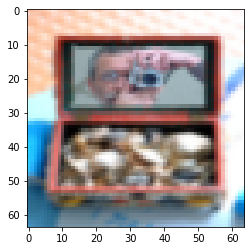

In [ ]:
# Example of a picture
index = 15
plt.imshow(train_x_orig[index])
print ("y = " + str(train_y[0,index]) + ". It's a " + classes[train_y[0,index]].decode("utf-8") +  " picture.")

In [ ]:
# Explore your dataset
m_train = train_x_orig.shape[0]
num_px = train_x_orig.shape[1]
m_test = test_x_orig.shape[0]

print ("Number of training examples: " + str(m_train))
print ("Number of testing examples: " + str(m_test))
print ("Each image is of size: (" + str(num_px) + ", " + str(num_px) + ", 3)")
print ("train_x_orig shape: " + str(train_x_orig.shape))
print ("train_y shape: " + str(train_y.shape))
print ("test_x_orig shape: " + str(test_x_orig.shape))
print ("test_y shape: " + str(test_y.shape))

Number of training examples: 209
Number of testing examples: 50
Each image is of size: (64, 64, 3)
train_x_orig shape: (209, 64, 64, 3)
train_y shape: (1, 209)
test_x_orig shape: (50, 64, 64, 3)
test_y shape: (1, 50)


In [ ]:
# Reshape the training and test examples
train_x_flatten = train_x_orig.reshape(train_x_orig.shape[0], -1).T   # The "-1" makes reshape flatten the remaining dimensions
test_x_flatten = test_x_orig.reshape(test_x_orig.shape[0], -1).T

# Standardize data to have feature values between 0 and 1.
train_x = train_x_flatten/255.
test_x = test_x_flatten/255.

print ("train_x's shape: " + str(train_x.shape))
print ("test_x's shape: " + str(test_x.shape))


train_x's shape: (12288, 209)
test_x's shape: (12288, 50)


# PART B — 5-Layer Neural Network with Regularization + Cross Validation

Everything below is built **from scratch with NumPy only** (no Keras / PyTorch / sklearn), in the same style as the helper functions above (`linear_forward`, `relu`, `sigmoid_backward`, `linear_backward` ... are re-used directly).

**Network:** `[LINEAR -> (BatchNorm) -> RELU -> (Dropout)] x 4 -> LINEAR -> SIGMOID`  → **5 weight layers** (`layer_dims = [12288, 20, 10, 7, 5, 1]`).

**Experiments (each evaluated with K-fold cross validation):**

| # | Technique | Settings |
|---|-----------|----------|
| 0 | Baseline (no regularization) | – |
| 1 | LASSO  (L1) | λ |
| 2 | RIDGE  (L2) | λ |
| 3 | Elastic Net (L1 + L2) | λ, α |
| 4 | Dropout | drop-probability 0.1, 0.2, 0.3, 0.4, 0.5 |
| 5 | DropConnect | drop-probability 0.2, 0.4, 0.5 |
| 6 | Batch Normalization | – |

**Regularized cost used** (m = number of training examples, `CE` = cross-entropy from Section 6):

$$J = CE + \underbrace{\frac{\lambda}{m}\sum_l \|W^{[l]}\|_1}_{\text{LASSO}} \quad , \quad J = CE + \underbrace{\frac{\lambda}{2m}\sum_l \|W^{[l]}\|_2^2}_{\text{RIDGE}} \quad , \quad J = CE + \frac{\lambda}{m}\sum_l\Big[\alpha\|W^{[l]}\|_1 + \frac{1-\alpha}{2}\|W^{[l]}\|_2^2\Big]_{\text{Elastic Net}}$$

Gradient added to `dW[l]`:  LASSO → $\frac{\lambda}{m}\,\text{sign}(W)$,  RIDGE → $\frac{\lambda}{m}W$,  Elastic Net → $\frac{\lambda}{m}\big(\alpha\,\text{sign}(W) + (1-\alpha)W\big)$.

**How "variance" is reported** (printed for every experiment):
1. **Generalisation variance (accuracy gap)** = average train accuracy − average test accuracy (the usual bias/variance reading: big gap ⇒ high variance / over-fitting).
2. **Loss gap** = final test loss − final train loss.
3. **Fold variance** = variance of the test accuracy across the K cross-validation folds (stability of the model).

In [ ]:
# ---------------- Global settings for the experiments (change here to tune) ----------------
np.seterr(over='ignore')                      # np.exp overflow inside sigmoid is harmless here

LAYER_DIMS     = [12288, 20, 10, 7, 5, 1]     # 5 weight layers  (4 x RELU hidden + 1 x SIGMOID output)
K_FOLDS        = 5                            # number of cross-validation folds
LEARNING_RATE  = 0.0075
NUM_ITERATIONS = 1500                         # gradient-descent iterations per fold
RECORD_EVERY   = 10                           # store the loss curve every 10 iterations

LAMBDA_L1      = 0.1                          # LASSO strength
LAMBDA_L2      = 1.0                          # RIDGE strength
LAMBDA_EN      = 0.5                          # Elastic-Net strength
ALPHA_EN       = 0.5                          # Elastic-Net mix (1 = pure LASSO, 0 = pure RIDGE)

## 8 - Data for Cross Validation

Cross validation needs one pool of labelled examples, so the given train set (209) and test set (50) are merged into 259 images.
In every fold, 1 part is held out as the **test fold** and the remaining parts are used for **training**.

In [ ]:
X_all = np.concatenate((train_x, test_x), axis=1)     # (12288, 259)
Y_all = np.concatenate((train_y, test_y), axis=1)     # (1, 259)

print("X_all shape:", X_all.shape)
print("Y_all shape:", Y_all.shape)
print("Cats: %d , Non-cats: %d" % (np.sum(Y_all == 1), np.sum(Y_all == 0)))

## 9 - Extra building blocks

### 9.1 He initialization
The original `initialize_parameters_deep` scales weights by `0.01`, which makes a 5-layer ReLU network learn very slowly (the activations shrink layer after layer). For this deeper model we scale by $\sqrt{2/n^{[l-1]}}$ (He initialization). Batch-norm parameters $\gamma$ (scale, init 1) and $\beta$ (shift, init 0) are created for every hidden layer when Batch Norm is on.

In [ ]:
def initialize_parameters_he(layer_dims, use_batchnorm=False, seed=1):
    np.random.seed(seed)
    parameters = {}
    L = len(layer_dims) - 1                               # number of weight layers

    for l in range(1, L + 1):
        parameters['W' + str(l)] = np.random.randn(layer_dims[l], layer_dims[l-1]) * np.sqrt(2. / layer_dims[l-1])
        parameters['b' + str(l)] = np.zeros((layer_dims[l], 1))

        if use_batchnorm and l < L:                       # no batch-norm on the output layer
            parameters['gamma' + str(l)] = np.ones((layer_dims[l], 1))
            parameters['beta'  + str(l)] = np.zeros((layer_dims[l], 1))

    return parameters


def initialize_bn_state(layer_dims):
    # running mean / variance used by batch-norm at prediction time
    bn_state = {}
    for l in range(1, len(layer_dims) - 1):
        bn_state['mean' + str(l)] = np.zeros((layer_dims[l], 1))
        bn_state['var'  + str(l)] = np.ones((layer_dims[l], 1))
    return bn_state


p = initialize_parameters_he([5, 4, 3, 1], use_batchnorm=True)
print({k: v.shape for k, v in p.items()})

### 9.2 Batch Normalization (forward and backward)

For a layer's pre-activation $Z$ of shape (units, m), per unit:

$$\mu=\frac1m\sum_i Z^{(i)},\quad \sigma^2=\frac1m\sum_i (Z^{(i)}-\mu)^2,\quad \hat Z=\frac{Z-\mu}{\sqrt{\sigma^2+\epsilon}},\quad \tilde Z=\gamma\hat Z+\beta$$

* **Training:** uses the mini-batch statistics $\mu,\sigma^2$ and updates running averages.
* **Testing:** uses the running averages.

Backward (as in the original paper), with `dZt` = gradient w.r.t. $\tilde Z$:

$$d\gamma=\tfrac1m\sum dZ_t\hat Z,\quad d\beta=\tfrac1m\sum dZ_t,\quad d\hat Z=dZ_t\,\gamma$$
$$d\sigma^2=\sum d\hat Z\,(Z-\mu)\,\big(-\tfrac12\big)(\sigma^2+\epsilon)^{-3/2},\quad d\mu=\sum d\hat Z\,\tfrac{-1}{\sqrt{\sigma^2+\epsilon}}+d\sigma^2\,\tfrac{\sum -2(Z-\mu)}{m}$$
$$dZ=\frac{d\hat Z}{\sqrt{\sigma^2+\epsilon}}+d\sigma^2\,\frac{2(Z-\mu)}{m}+\frac{d\mu}{m}$$

(The `1/m` factor of the cost is applied in `dgamma`/`dbeta`, exactly as `linear_backward` applies it to `dW`/`db`.)

In [ ]:
def batchnorm_forward(Z, gamma, beta, bn_state, l, training, momentum=0.9, eps=1e-8):
    m = Z.shape[1]

    if training:
        mu  = np.sum(Z, axis=1, keepdims=True) / m
        var = np.sum((Z - mu) ** 2, axis=1, keepdims=True) / m

        if bn_state is not None:                         # exponential moving average for test time
            bn_state['mean' + str(l)] = momentum * bn_state['mean' + str(l)] + (1 - momentum) * mu
            bn_state['var'  + str(l)] = momentum * bn_state['var'  + str(l)] + (1 - momentum) * var
    else:
        mu  = bn_state['mean' + str(l)]
        var = bn_state['var'  + str(l)]

    Z_norm  = (Z - mu) / np.sqrt(var + eps)
    Z_tilde = gamma * Z_norm + beta

    cache = (Z, Z_norm, mu, var, gamma, eps)
    return Z_tilde, cache


def batchnorm_backward(dZ_tilde, cache):
    Z, Z_norm, mu, var, gamma, eps = cache
    m = Z.shape[1]

    dgamma = np.sum(dZ_tilde * Z_norm, axis=1, keepdims=True) / m
    dbeta  = np.sum(dZ_tilde, axis=1, keepdims=True) / m

    dZ_norm = dZ_tilde * gamma
    dvar = np.sum(dZ_norm * (Z - mu) * (-0.5) * (var + eps) ** (-1.5), axis=1, keepdims=True)
    dmu  = np.sum(dZ_norm * (-1. / np.sqrt(var + eps)), axis=1, keepdims=True) \
           + dvar * np.sum(-2. * (Z - mu), axis=1, keepdims=True) / m

    dZ = dZ_norm / np.sqrt(var + eps) + dvar * 2. * (Z - mu) / m + dmu / m
    return dZ, dgamma, dbeta

## 10 - Forward propagation with Dropout, DropConnect and Batch Norm

`config` is a small dictionary that switches every technique on/off:

```python
config = {'reg': 'none'|'l1'|'l2'|'elastic', 'lambd': .., 'alpha': ..,
          'dropout': p_drop, 'dropconnect': p_drop, 'batchnorm': True/False}
```

For each hidden layer the order of operations is:

`DropConnect(W)  ->  Z = W A_prev + b  ->  BatchNorm(Z)  ->  ReLU  ->  Dropout(A)`

* **Dropout (inverted):** each *activation* is kept with probability `keep = 1 - p`; kept ones are divided by `keep`, so nothing needs to be rescaled at test time.
* **DropConnect (inverted):** each *weight* (connection) is kept with probability `keep = 1 - p` and scaled by `1/keep` for that forward pass. The same mask is re-used in back-prop.
* Neither is applied when `training=False` (prediction), and neither is applied to the output layer.

In [ ]:
def make_config(reg='none', lambd=0.0, alpha=0.5, dropout=0.0, dropconnect=0.0, batchnorm=False):
    return {'reg': reg, 'lambd': lambd, 'alpha': alpha,
            'dropout': dropout, 'dropconnect': dropconnect, 'batchnorm': batchnorm}


def model_forward(X, parameters, config, bn_state=None, training=True):
    caches = []
    A = X
    L = sum(1 for k in parameters if k.startswith('W'))          # number of weight layers

    # ---- [DropConnect -> LINEAR -> BatchNorm -> RELU -> Dropout] x (L-1) ----
    for l in range(1, L):
        A_prev = A
        W = parameters['W' + str(l)]
        b = parameters['b' + str(l)]

        # DropConnect: randomly drop individual weights (connections)
        M = None
        if training and config['dropconnect'] > 0:
            keep = 1. - config['dropconnect']
            M = (np.random.rand(W.shape[0], W.shape[1]) < keep) / keep     # scaled binary mask
            W_used = W * M
        else:
            W_used = W

        Z, linear_cache = linear_forward(A_prev, W_used, b)

        # Batch normalization
        bn_cache = None
        if config['batchnorm']:
            Z, bn_cache = batchnorm_forward(Z, parameters['gamma' + str(l)], parameters['beta' + str(l)],
                                            bn_state, l, training)

        A, act_cache = relu(Z)

        # Dropout: randomly drop activations (neurons)
        D = None
        if training and config['dropout'] > 0:
            keep = 1. - config['dropout']
            D = (np.random.rand(A.shape[0], A.shape[1]) < keep) / keep     # scaled binary mask
            A = A * D

        caches.append({'linear': linear_cache, 'act': act_cache, 'bn': bn_cache, 'D': D, 'M': M})

    # ---- LINEAR -> SIGMOID (output layer, no dropout / batch-norm) ----
    AL, cache = linear_activation_forward(A, parameters['W' + str(L)], parameters['b' + str(L)], activation="sigmoid")
    caches.append({'linear': cache[0], 'act': cache[1], 'bn': None, 'D': None, 'M': None})

    return AL, caches

## 11 - Cost function with LASSO / RIDGE / Elastic-Net penalty

In [ ]:
def compute_regularization_cost(parameters, config, m):
    L = sum(1 for k in parameters if k.startswith('W'))
    l1 = 0.
    l2 = 0.
    for l in range(1, L + 1):
        W = parameters['W' + str(l)]
        l1 += np.sum(np.abs(W))
        l2 += np.sum(np.square(W))

    lam, a = config['lambd'], config['alpha']
    if config['reg'] == 'l1':
        return lam / m * l1
    elif config['reg'] == 'l2':
        return lam / (2 * m) * l2
    elif config['reg'] == 'elastic':
        return lam / m * (a * l1 + (1 - a) * 0.5 * l2)
    return 0.


def regularization_gradient(W, config, m):
    lam, a = config['lambd'], config['alpha']
    if config['reg'] == 'l1':
        return lam / m * np.sign(W)
    elif config['reg'] == 'l2':
        return lam / m * W
    elif config['reg'] == 'elastic':
        return lam / m * (a * np.sign(W) + (1 - a) * W)
    return 0.


def compute_cost_with_regularization(AL, Y, parameters, config):
    m = Y.shape[1]
    AL_safe = np.clip(AL, 1e-10, 1 - 1e-10)              # avoid log(0)
    ce = compute_cost(AL_safe, Y)                         # cross-entropy from Section 6
    total = ce + compute_regularization_cost(parameters, config, m)
    return float(ce), float(total)

## 12 - Backward propagation
Mirrors `L_model_backward`, but additionally:
* multiplies `dA` by the (scaled) **dropout mask** before the ReLU derivative,
* back-propagates through **batch norm** (also giving `dgamma`, `dbeta`),
* multiplies `dW` by the (scaled) **DropConnect mask**,
* adds the **LASSO / RIDGE / Elastic-Net** gradient to every `dW`.

In [ ]:
def model_backward(AL, Y, caches, parameters, config):
    grads = {}
    L = len(caches)
    m = AL.shape[1]
    Y = Y.reshape(AL.shape)

    AL = np.clip(AL, 1e-10, 1 - 1e-10)
    dAL = - (np.divide(Y, AL) - np.divide(1 - Y, 1 - AL))

    # ---- output layer: SIGMOID -> LINEAR ----
    c = caches[L-1]
    dZ = sigmoid_backward(dAL, c['act'])
    dA, dW, db = linear_backward(dZ, c['linear'])
    grads['dW' + str(L)] = dW
    grads['db' + str(L)] = db

    # ---- hidden layers: Dropout -> RELU -> BatchNorm -> LINEAR -> DropConnect ----
    for l in reversed(range(1, L)):
        c = caches[l-1]

        if c['D'] is not None:                            # dropout
            dA = dA * c['D']

        dZ = relu_backward(dA, c['act'])

        if c['bn'] is not None:                           # batch norm
            dZ, dgamma, dbeta = batchnorm_backward(dZ, c['bn'])
            grads['dgamma' + str(l)] = dgamma
            grads['dbeta'  + str(l)] = dbeta

        dA, dW, db = linear_backward(dZ, c['linear'])

        if c['M'] is not None:                            # dropconnect: only kept connections get gradient
            dW = dW * c['M']

        grads['dW' + str(l)] = dW
        grads['db' + str(l)] = db

    # ---- regularization gradient (LASSO / RIDGE / Elastic Net) ----
    if config['reg'] != 'none':
        for l in range(1, L + 1):
            grads['dW' + str(l)] = grads['dW' + str(l)] + regularization_gradient(parameters['W' + str(l)], config, m)

    return grads


def update_parameters_reg(parameters, grads, learning_rate):
    # generic gradient descent: works for W, b (and gamma, beta when batch-norm is used)
    for key in grads:
        parameters[key[1:]] = parameters[key[1:]] - learning_rate * grads[key]     # 'dW1' -> 'W1'
    return parameters

## 13 - Predict, Train

`train_model` runs gradient descent and records
* the **training loss** (the quantity being minimised: cross-entropy + penalty, measured on the training pass), and
* the **test-fold loss** (pure cross-entropy in prediction mode: no dropout / DropConnect, running batch-norm statistics),

every `RECORD_EVERY` iterations.

In [ ]:
def predict_model(X, parameters, config, bn_state):
    probas, _ = model_forward(X, parameters, config, bn_state, training=False)
    return (probas > 0.5).astype(float), probas


def accuracy(p, Y):
    return float(np.sum(p == Y) / Y.shape[1])


def train_model(X, Y, layer_dims, config, X_val, Y_val, learning_rate=0.0075,
                num_iterations=1500, record_every=10, seed=1):
    parameters = initialize_parameters_he(layer_dims, config['batchnorm'], seed=1)
    bn_state = initialize_bn_state(layer_dims) if config['batchnorm'] else None
    np.random.seed(seed)                                  # controls the dropout / dropconnect masks

    iters, train_losses, val_losses = [], [], []

    for i in range(num_iterations):
        # Forward propagation
        AL, caches = model_forward(X, parameters, config, bn_state, training=True)

        # Cost (cross-entropy + penalty)
        ce, cost = compute_cost_with_regularization(AL, Y, parameters, config)

        # Backward propagation
        grads = model_backward(AL, Y, caches, parameters, config)

        # Update parameters
        parameters = update_parameters_reg(parameters, grads, learning_rate)

        if i % record_every == 0 or i == num_iterations - 1:
            AL_val, _ = model_forward(X_val, parameters, config, bn_state, training=False)
            val_ce, _ = compute_cost_with_regularization(AL_val, Y_val, parameters, config)
            iters.append(i)
            train_losses.append(cost)
            val_losses.append(val_ce)

    return parameters, bn_state, iters, train_losses, val_losses

### 13.1 Sanity check: numerical gradient check
Before trusting the new back-prop (batch-norm + Elastic-Net penalty), compare it with a numerical gradient
$\frac{J(\theta+\varepsilon)-J(\theta-\varepsilon)}{2\varepsilon}$ on a tiny random network. (Dropout / DropConnect are random, so they are switched off for this check.)
The relative difference should be tiny (≈ 1e-6 or less).

In [ ]:
def gradient_check(config, layer_dims=(6, 5, 4, 3, 2, 1), m=12, epsilon=1e-6):
    np.random.seed(0)
    Xc = np.random.randn(layer_dims[0], m)
    Yc = (np.random.rand(1, m) > 0.5).astype(float)
    params = initialize_parameters_he(list(layer_dims), config['batchnorm'], seed=2)
    # make the check non-trivial (nonzero biases / gammas / betas)
    for k in params:
        if k.startswith('b') or k.startswith('beta'):
            params[k] = params[k] + 0.1 * np.random.randn(*params[k].shape)
        if k.startswith('gamma'):
            params[k] = params[k] + 0.1 * np.random.randn(*params[k].shape)

    def cost_fn(p):
        AL, _ = model_forward(Xc, p, config, None, training=True)
        return compute_cost_with_regularization(AL, Yc, p, config)[1]

    AL, caches = model_forward(Xc, params, config, None, training=True)
    grads = model_backward(AL, Yc, caches, params, config)

    num, ana = [], []
    for gkey in grads:
        pkey = gkey[1:]
        P = params[pkey]
        for idx in np.ndindex(*P.shape):
            old = P[idx]
            P[idx] = old + epsilon; jp = cost_fn(params)
            P[idx] = old - epsilon; jm = cost_fn(params)
            P[idx] = old
            num.append((jp - jm) / (2 * epsilon))
            ana.append(grads[gkey][idx])

    num, ana = np.array(num), np.array(ana)
    diff = np.linalg.norm(num - ana) / (np.linalg.norm(num) + np.linalg.norm(ana))
    return diff


for name, cfg in [("plain",            make_config()),
                  ("batch-norm",       make_config(batchnorm=True)),
                  ("LASSO (L1)",       make_config(reg='l1', lambd=2.0)),
                  ("RIDGE (L2)",       make_config(reg='l2', lambd=2.0)),
                  ("Elastic Net + BN", make_config(reg='elastic', lambd=2.0, alpha=0.5, batchnorm=True))]:
    print("%-18s relative difference = %.2e" % (name, gradient_check(cfg)))

## 14 - K-Fold Cross Validation

1. Shuffle the 259 indices once (fixed seed) and split them into `K_FOLDS` nearly equal folds.
2. For every fold: train on the other folds, hold this fold out as the test fold.
3. For every fold record: train accuracy, test accuracy, final train loss, final test loss, and the loss curves.
4. Report the averages and the **variance** measures described at the top.

Accuracies are always measured in prediction mode (no dropout / DropConnect), on the whole training part and on the held-out fold.

In [ ]:
def k_fold_split(m, k, seed=1):
    np.random.seed(seed)
    idx = np.random.permutation(m)
    folds = []
    start = 0
    for i in range(k):
        size = m // k + (1 if i < m % k else 0)           # spread the remainder
        folds.append(idx[start:start + size])
        start += size
    return folds


def cross_validate(X, Y, layer_dims, config, k=5, learning_rate=0.0075,
                   num_iterations=1500, record_every=10):
    m = X.shape[1]
    folds = k_fold_split(m, k)

    res = {'train_acc': [], 'test_acc': [], 'train_loss_final': [], 'test_loss_final': [],
           'train_curves': [], 'val_curves': [], 'iters': None}

    for f in range(k):
        test_idx  = folds[f]
        train_idx = np.concatenate([folds[j] for j in range(k) if j != f])

        X_tr, Y_tr = X[:, train_idx], Y[:, train_idx]
        X_te, Y_te = X[:, test_idx],  Y[:, test_idx]

        parameters, bn_state, iters, tr_curve, va_curve = train_model(
            X_tr, Y_tr, layer_dims, config, X_te, Y_te,
            learning_rate=learning_rate, num_iterations=num_iterations,
            record_every=record_every, seed=f + 1)

        p_tr, pr_tr = predict_model(X_tr, parameters, config, bn_state)
        p_te, pr_te = predict_model(X_te, parameters, config, bn_state)

        res['train_acc'].append(accuracy(p_tr, Y_tr))
        res['test_acc'].append(accuracy(p_te, Y_te))
        res['train_loss_final'].append(compute_cost_with_regularization(pr_tr, Y_tr, parameters, config)[0])
        res['test_loss_final'].append(compute_cost_with_regularization(pr_te, Y_te, parameters, config)[0])
        res['train_curves'].append(tr_curve)
        res['val_curves'].append(va_curve)
        res['iters'] = iters

        print("   fold %d/%d  train acc = %.4f   test acc = %.4f" % (f + 1, k, res['train_acc'][-1], res['test_acc'][-1]))

    # ---- summary statistics ----
    res['avg_train_acc']  = float(np.mean(res['train_acc']))
    res['avg_test_acc']   = float(np.mean(res['test_acc']))
    res['variance_gap']   = res['avg_train_acc'] - res['avg_test_acc']            # generalisation variance
    res['loss_gap']       = float(np.mean(res['test_loss_final']) - np.mean(res['train_loss_final']))
    res['fold_variance']  = float(np.var(res['test_acc']))                        # variance of test acc over folds
    res['avg_train_loss'] = float(np.mean(res['train_loss_final']))
    res['avg_test_loss']  = float(np.mean(res['test_loss_final']))
    return res


def plot_loss(res, title):
    iters = np.array(res['iters'])
    tr = np.array(res['train_curves'])                    # (folds, points)
    va = np.array(res['val_curves'])
    tr_m, tr_s = np.mean(tr, axis=0), np.std(tr, axis=0)
    va_m, va_s = np.mean(va, axis=0), np.std(va, axis=0)

    plt.figure(figsize=(7, 4.5))
    plt.plot(iters, tr_m, label='Training loss (mean of folds)', color='tab:blue')
    plt.fill_between(iters, tr_m - tr_s, tr_m + tr_s, color='tab:blue', alpha=0.2)
    plt.plot(iters, va_m, label='Test-fold loss (mean of folds)', color='tab:red', linestyle='--')
    plt.fill_between(iters, va_m - va_s, va_m + va_s, color='tab:red', alpha=0.15)
    plt.xlabel('iterations')
    plt.ylabel('loss')
    plt.title(title)
    plt.legend()
    plt.grid(alpha=0.3)
    plt.show()


def print_report(name, res):
    print("-" * 70)
    print("RESULT : " + name)
    print("  Average TRAIN accuracy            : %.4f" % res['avg_train_acc'])
    print("  Average TEST  accuracy            : %.4f" % res['avg_test_acc'])
    print("  Final VARIANCE (train acc - test acc) : %.4f" % res['variance_gap'])
    print("  Final loss gap (test - train loss)    : %.4f   (train loss %.4f, test loss %.4f)"
          % (res['loss_gap'], res['avg_train_loss'], res['avg_test_loss']))
    print("  Variance of test accuracy over folds  : %.6f" % res['fold_variance'])
    print("-" * 70)


all_results = {}          # name -> results dictionary (used for the final comparison)

def run_experiment(name, config):
    print("=" * 70)
    print("EXPERIMENT : " + name)
    print("=" * 70)
    res = cross_validate(X_all, Y_all, LAYER_DIMS, config, k=K_FOLDS,
                         learning_rate=LEARNING_RATE, num_iterations=NUM_ITERATIONS,
                         record_every=RECORD_EVERY)
    all_results[name] = res
    print_report(name, res)
    plot_loss(res, name)
    return res

## 15 - Experiments

### 15.0 Baseline: 5-layer network without any regularization

In [ ]:
res = run_experiment("Baseline (no regularization)", make_config())

### 15.1 LASSO (L1) regularization

In [ ]:
res = run_experiment("LASSO (L1), lambda=%g" % LAMBDA_L1, make_config(reg='l1', lambd=LAMBDA_L1))

### 15.2 RIDGE (L2) regularization

In [ ]:
res = run_experiment("RIDGE (L2), lambda=%g" % LAMBDA_L2, make_config(reg='l2', lambd=LAMBDA_L2))

### 15.3 Elastic Net (L1 + L2) regularization

In [ ]:
res = run_experiment("Elastic Net, lambda=%g, alpha=%g" % (LAMBDA_EN, ALPHA_EN),
                     make_config(reg='elastic', lambd=LAMBDA_EN, alpha=ALPHA_EN))

### 15.4 Dropout  (drop-probability 0.1, 0.2, 0.3, 0.4, 0.5)

In [ ]:
for p_drop in [0.1, 0.2, 0.3, 0.4, 0.5]:
    res = run_experiment("Dropout p=%.1f" % p_drop, make_config(dropout=p_drop))

### 15.5 DropConnect  (drop-probability 0.2, 0.4, 0.5)

In [ ]:
for p_drop in [0.2, 0.4, 0.5]:
    res = run_experiment("DropConnect p=%.1f" % p_drop, make_config(dropconnect=p_drop))

### 15.6 Batch Normalization

In [ ]:
res = run_experiment("Batch Normalization", make_config(batchnorm=True))

## 16 - Comparison of all experiments

In [ ]:
header = "%-36s %10s %10s %12s %10s %14s" % ("Method", "Avg Train", "Avg Test", "Variance", "Loss gap", "Fold var(test)")
print(header)
print("-" * len(header))
for name, r in all_results.items():
    print("%-36s %10.4f %10.4f %12.4f %10.4f %14.6f" %
          (name, r['avg_train_acc'], r['avg_test_acc'], r['variance_gap'], r['loss_gap'], r['fold_variance']))
print("\nVariance = avg train accuracy - avg test accuracy (lower = less over-fitting)")

In [ ]:
names = list(all_results.keys())
tr_acc = [all_results[n]['avg_train_acc'] for n in names]
te_acc = [all_results[n]['avg_test_acc'] for n in names]
gap    = [all_results[n]['variance_gap'] for n in names]
pos    = np.arange(len(names))

plt.figure(figsize=(12, 9))

plt.subplot(3, 1, 1)
plt.bar(pos - 0.2, tr_acc, width=0.4, label='Avg train accuracy')
plt.bar(pos + 0.2, te_acc, width=0.4, label='Avg test accuracy')
plt.xticks(pos, [""] * len(names))
plt.ylabel('accuracy')
plt.title('Cross-validated accuracy')
plt.legend()

plt.subplot(3, 1, 2)
plt.bar(pos, gap, color='tab:orange')
plt.xticks(pos, [""] * len(names))
plt.ylabel('train acc - test acc')
plt.title('Final variance (generalisation gap)')

plt.subplot(3, 1, 3)
for n in names:
    r = all_results[n]
    plt.plot(r['iters'], np.mean(np.array(r['train_curves']), axis=0), label=n)
plt.xlabel('iterations')
plt.ylabel('training loss')
plt.title('Training loss of every experiment (mean over folds)')
plt.legend(fontsize=7, ncol=3)
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

print("Bar order (left -> right):")
for i, n in enumerate(names):
    print("  %2d. %s" % (i + 1, n))

### Reading the results
* **Baseline** normally shows a train accuracy near 1.0 and a much lower test accuracy → high variance (large gap).
* **LASSO / RIDGE / Elastic Net** shrink the weights (LASSO also drives many exactly towards 0); a bigger `lambda` reduces the gap but too big a value under-fits (both accuracies fall).
* **Dropout / DropConnect** add noise during training, so the *training* loss curve is higher and noisier, while the gap between train and test accuracy shrinks; large drop-probabilities on the very narrow layers (5–7 units) can start to under-fit.
* **Batch Normalization** speeds up the fall of the loss and adds a small regularizing effect through the mini-batch statistics.

Hyper-parameters (`LAMBDA_*`, `NUM_ITERATIONS`, `LEARNING_RATE`, `K_FOLDS`) are collected in the settings cell of Part B; change them and re-run to explore.